# Analyse exploratoire (EDA) — ShopPulse

**Objectif** : comprendre les commandes livrées avant de construire la segmentation et les modèles.

1. Distributions (prix, délai de livraison, notes)
2. Saisonnalité (mois, jour de la semaine)
3. Géographie (commandes et retards par état)
4. Deux tests statistiques

Source : schéma `clean` de PostgreSQL, alimenté par le pipeline `pipelines/etl_flow.py`.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
from sqlalchemy import create_engine

# On se place à la racine du projet pour que le fichier .env soit trouvé
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

from shoppulse.config import settings

engine = create_engine(settings.database_url)

## Chargement des données

Une ligne par commande livrée, avec l'état du client, le montant, les frais de port et la note de l'avis.

In [2]:
requete = """
SELECT
    o.order_id,
    o.order_purchase_timestamp,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date,
    c.customer_state,
    i.prix_total,
    i.frais_port,
    r.note
FROM clean.orders o
JOIN clean.customers c ON c.customer_id = o.customer_id
JOIN (
    SELECT order_id, SUM(price) AS prix_total, SUM(freight_value) AS frais_port
    FROM clean.order_items
    GROUP BY order_id
) i ON i.order_id = o.order_id
LEFT JOIN (
    SELECT order_id, AVG(review_score) AS note
    FROM clean.order_reviews
    GROUP BY order_id
) r ON r.order_id = o.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
"""

df = pd.read_sql(requete, engine)

# Nouvelles colonnes
df["delai_livraison_jours"] = (
    df["order_delivered_customer_date"] - df["order_purchase_timestamp"]
).dt.days
df["en_retard"] = df["order_delivered_customer_date"] > df["order_estimated_delivery_date"]

print(df.shape)
df.head()

(96470, 10)


,order_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,customer_state,prix_total,frais_port,note,delai_livraison_jours,en_retard
0,00010242fe8c5a6d1ba2dd792cb16214,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,RJ,58.90,13.29,5.0,7,False
1,00018f77f2f0320c557190d7a144bdd3,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,SP,239.90,19.93,4.0,16,False
2,000229ec398224ef6ca0657da4fc703e,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,MG,199.00,17.87,5.0,7,False
3,00024acbcdf0a6daa1e931b038114c75,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20,SP,12.99,12.79,4.0,6,False
4,00042b26cf59d7ce69dfabb4e55b4fd9,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17,SP,199.90,18.14,5.0,25,False


In [3]:
df[["prix_total", "frais_port", "delai_livraison_jours", "note"]].describe().round(1)

,prix_total,frais_port,delai_livraison_jours,note
count,96470.0,96470.0,96470.0,95824.0
mean,137.0,22.8,12.1,4.2
std,209.1,21.6,9.6,1.3
min,0.8,0.0,0.0,1.0
25%,45.9,13.8,6.0,4.0
50%,86.5,17.2,10.0,5.0
75%,149.9,24.0,15.0,5.0
max,13440.0,1795.0,209.0,5.0


## 1. Distributions

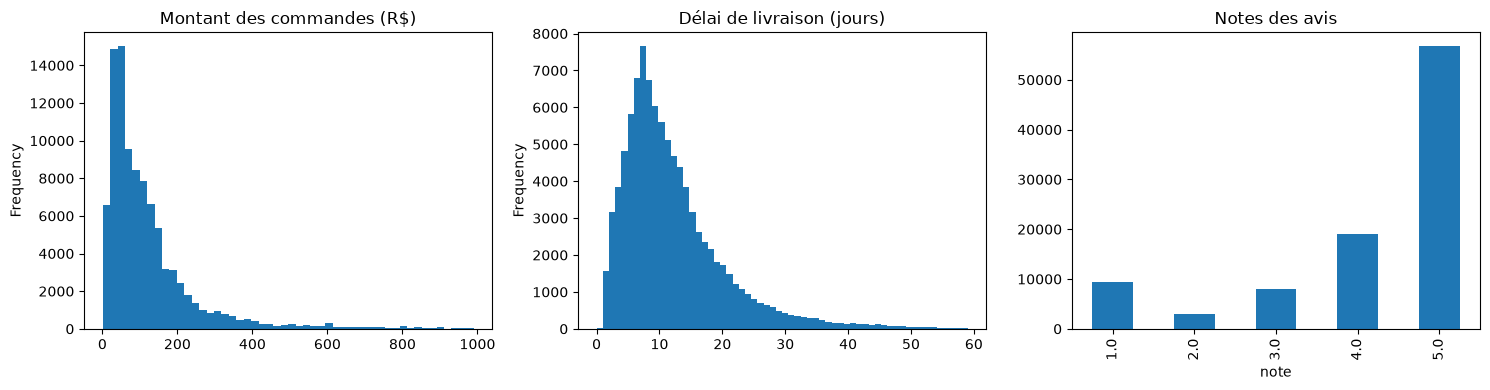

Montant médian : 86.5 R$
Délai médian : 10.0 jours
Part des commandes en retard : 8.1 %


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Prix : on coupe les 1 % les plus chers pour que le graphique reste lisible
limite = df["prix_total"].quantile(0.99)
df[df["prix_total"] < limite]["prix_total"].plot.hist(bins=50, ax=axes[0])
axes[0].set_title("Montant des commandes (R$)")

df[df["delai_livraison_jours"] < 60]["delai_livraison_jours"].plot.hist(bins=60, ax=axes[1])
axes[1].set_title("Délai de livraison (jours)")

df["note"].round().value_counts().sort_index().plot.bar(ax=axes[2])
axes[2].set_title("Notes des avis")

plt.tight_layout()
plt.show()

print("Montant médian :", round(df["prix_total"].median(), 2), "R$")
print("Délai médian :", df["delai_livraison_jours"].median(), "jours")
print("Part des commandes en retard :", round(100 * df["en_retard"].mean(), 1), "%")

**Lecture** :
- **Montants** : distribution très asymétrique. La médiane est de 86,5 R$ mais la moyenne monte à 137 R$, tirée par quelques grosses commandes (jusqu'à 13 440 R$). Il faudra raisonner en médiane et passer au logarithme pour le clustering.
- **Délai de livraison** : 10 jours en médiane (12,1 en moyenne), avec une longue traîne jusqu'à plus de 200 jours.
- **Notes** : très majoritairement 5/5, mais un second pic à 1/5 (environ 9 500 avis) : les clients mécontents le sont fortement. Les classes du modèle de sentiment seront déséquilibrées.
- **8,1 %** des commandes livrées arrivent en retard : la classe « retard » est minoritaire, il faudra des métriques adaptées (rappel, F1) et pas seulement l'accuracy.

## 2. Saisonnalité

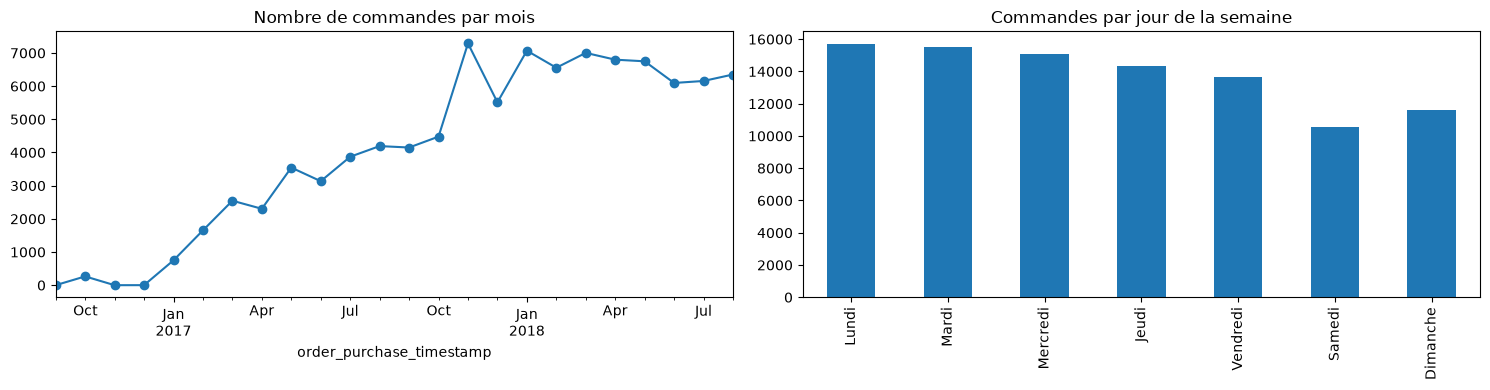

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

par_mois = df.set_index("order_purchase_timestamp").resample("MS")["order_id"].count()
par_mois.plot(ax=axes[0], marker="o")
axes[0].set_title("Nombre de commandes par mois")

jours = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
par_jour = df["order_purchase_timestamp"].dt.day_of_week.value_counts().sort_index()
par_jour.index = jours
par_jour.plot.bar(ax=axes[1])
axes[1].set_title("Commandes par jour de la semaine")

plt.tight_layout()
plt.show()

**Lecture** :
- **Tendance** : forte croissance en 2017, de moins de 1 000 à plus de 4 000 commandes par mois, puis un plateau autour de 6 000 à 7 000 commandes par mois en 2018.
- **Pic de novembre 2017** (environ 7 300 commandes) : effet Black Friday.
- **Jour de la semaine** : le lundi et le mardi sont les plus actifs (environ 15 700 commandes le lundi), le week-end est le plus calme (environ 10 500 le samedi). Les campagnes marketing gagneront à partir en début de semaine.

## 3. Géographie

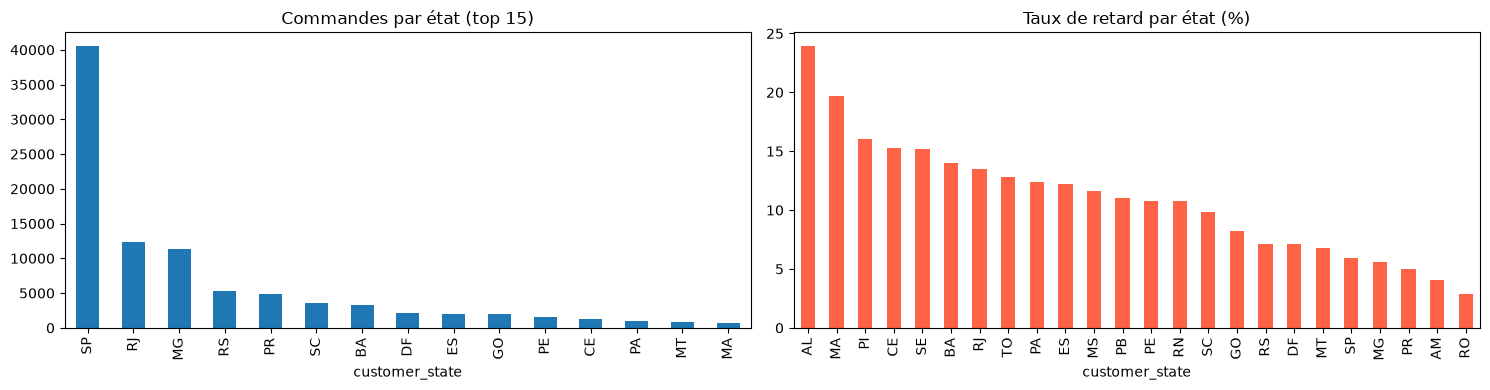

In [6]:
par_etat = df.groupby("customer_state").agg(
    nb_commandes=("order_id", "count"),
    taux_retard=("en_retard", "mean"),
)
par_etat["taux_retard"] = (100 * par_etat["taux_retard"]).round(1)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
par_etat["nb_commandes"].sort_values(ascending=False).head(15).plot.bar(ax=axes[0])
axes[0].set_title("Commandes par état (top 15)")

# On ne garde que les états avec au moins 100 commandes pour un taux fiable
fiables = par_etat[par_etat["nb_commandes"] >= 100]
fiables["taux_retard"].sort_values(ascending=False).plot.bar(ax=axes[1], color="tomato")
axes[1].set_title("Taux de retard par état (%)")

plt.tight_layout()
plt.show()

**Lecture** :
- **Concentration** : São Paulo (SP) pèse à lui seul environ 40 500 commandes, soit 42 % du total, devant RJ et MG.
- **Retards** : les états du Nord-Est sont les plus touchés (AL 23,9 %, MA 19,7 %, PI 16,0 %), alors que SP n'a que 5,9 % de retards. Les vendeurs étant surtout à SP, la distance joue probablement un rôle important.

## 4. Tests statistiques

Seuil de significativité choisi : **α = 0,05**.

### Test 1 — Les commandes en retard ont-elles de moins bonnes notes ?

- **H0** : les notes des commandes en retard et à l'heure suivent la même distribution.
- **H1** : les distributions sont différentes.
- **Test choisi : Mann-Whitney U**. Les notes vont de 1 à 5 (variable ordinale) et ne suivent pas une loi normale : un test de Student n'est donc pas adapté. Mann-Whitney compare les deux groupes sans supposer de loi normale.

In [7]:
avec_note = df.dropna(subset=["note"])
notes_retard = avec_note[avec_note["en_retard"]]["note"]
notes_heure = avec_note[~avec_note["en_retard"]]["note"]

print("Note moyenne en retard :", round(notes_retard.mean(), 2))
print("Note moyenne à l'heure :", round(notes_heure.mean(), 2))

resultat = stats.mannwhitneyu(notes_retard, notes_heure)
print("Statistique U :", resultat.statistic)
print("p-value :", resultat.pvalue)

if resultat.pvalue < 0.05:
    print("=> On rejette H0 : les retards ont un effet significatif sur les notes.")
else:
    print("=> On ne peut pas rejeter H0.")

Note moyenne en retard : 2.57
Note moyenne à l'heure : 4.29
Statistique U : 150680825.5
p-value : 0.0
=> On rejette H0 : les retards ont un effet significatif sur les notes.


### Test 2 — Le retard dépend-il de la région du client ?

On compare le **Nord-Est** (Nordeste) au reste du Brésil.

- **H0** : être en retard est indépendant de la région.
- **H1** : le retard dépend de la région.
- **Test choisi : Khi-deux d'indépendance**. On croise deux variables **catégorielles** (région, retard oui/non) : c'est le test adapté à un tableau de contingence.

In [8]:
nordeste = ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"]
df["region"] = df["customer_state"].apply(
    lambda etat: "Nord-Est" if etat in nordeste else "Reste du Brésil"
)

tableau = pd.crosstab(df["region"], df["en_retard"])
print(tableau)
print()
print("Taux de retard par région (%) :")
print((100 * df.groupby("region")["en_retard"].mean()).round(1))

chi2, p_value, ddl, attendus = stats.chi2_contingency(tableau)
print()
print("Khi-deux :", round(chi2, 1), "| degrés de liberté :", ddl)
print("p-value :", p_value)

if p_value < 0.05:
    print("=> On rejette H0 : le retard dépend de la région du client.")
else:
    print("=> On ne peut pas rejeter H0.")

en_retard        False  True 
region                       
Nord-Est          7748   1296
Reste du Brésil  80896   6530

Taux de retard par région (%) :
region
Nord-Est           14.3
Reste du Brésil     7.5
Name: en_retard, dtype: float64

Khi-deux : 516.6 | degrés de liberté : 1
p-value : 2.292884725816499e-114
=> On rejette H0 : le retard dépend de la région du client.


## Conclusions

- **Distributions** : montants très asymétriques (médiane 86,5 R$), délai médian de 10 jours, notes majoritairement à 5/5 avec un pic de mécontentement à 1/5.
- **Saisonnalité** : forte croissance en 2017, pic au Black Friday, plateau en 2018 ; activité plus forte en début de semaine.
- **Géographie** : 42 % des commandes viennent de SP ; le Nord-Est subit beaucoup plus de retards.
- **Test 1 (Mann-Whitney)** : p-value ≈ 0 → les commandes en retard ont des notes significativement plus basses (2,57 contre 4,29).
- **Test 2 (Khi-deux)** : χ² = 516,6, p-value ≈ 2 × 10⁻¹¹⁴ → le retard dépend de la région (14,3 % au Nord-Est contre 7,5 % ailleurs).

**Conséquences pour la suite** :
- Modèle de retard : utiliser la région et la distance client-vendeur comme variables ; classes déséquilibrées (8,1 % de retards) → rappel, F1 et pondération des classes.
- Audit d'équité : vérifier que le modèle n'est pas moins performant pour le Nord-Est.
- Segmentation RFM : passer les montants au logarithme avant le clustering.
- Sentiment : classes déséquilibrées (avis positifs très majoritaires).